# 09 — Demo en vivo: el agente aprendiendo, sobre `rcssserver`

Cubre el entregable *Visualización y Conexión a Docker*: se conecta el cliente Python al contenedor `rcssserver`
y se muestra en este cuaderno la trayectoria 2D del agente en distintos momentos de su aprendizaje.

1. **Chequeo de conexión** (`src/live_check.py`): handshake, reloj, reset, signo del giro y dash frente al modelo.
2. **El agente aprendiendo, en el servidor real.** La Q-table guardada tras N episodios de entrenamiento
   (0, 500, …) se ejecuta con su política greedy en `rcssserver`, siempre desde el mismo inicio. La trayectoria
   es la verdad de terreno del entrenador (coach offline). La política solo recibe lo que percibe el jugador.
3. **Animación** de esas trayectorias, a velocidad real (1 paso = 1 ciclo de 100 ms).

Cada episodio se ejecuta completo y se dibuja al terminar, nunca durante el episodio. Así el dibujo no retrasa
el ciclo de 100 ms del servidor. El contador de comandos perdidos lo comprueba.

**Antes de ejecutar:** `docker compose up -d` y `docker compose restart rcssserver`. El servidor acepta solo 11
conexiones de jugador por sesión, y este cuaderno usa 2. Tarda ≈ 1 min.

In [1]:
import json, os, subprocess
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, Markdown, display

os.chdir("/workspace") if os.path.isdir("/workspace/src") else None
from src import plots
from src.agents import GreedyQPolicy
from src.controllers import rollout
from src.discretizer import Discretizer, DiscretizerConfig
from src.env_base import ACTION_NAMES
from src.live_env import LiveBallPursuitEnv, ResetError
from src.live_eval import episode_record
from src.sampler import evaluation_starts

ART = "notebooks/artifacts"
POLICIES = {
    # Extensión: Q-Learning entrenado con la física del servidor (73.5 % en vivo). Recomendada para la demo.
    "servidor": f"{ART}/runs/qlearning_eps_decay_1.0_to_0.1/seed_4",
    # Resultado principal del informe: Q-Learning en el entorno del kit (R3). En el servidor captura ≈ 26 %.
    "kit": f"{ART}/runs_kit_final/kit_qlearning_eps_decay_1.0_to_0.1/seed_1",
}
POLICY = "servidor"
# Índice en evaluation_starts(200, seed=2026): 5 = balón atrás a la izquierda a 17.8 m (θ₀ = −110°).
# Otros: 44 = delante a 20 m, 0 = derecha a 11 m, 39 = atrás a la derecha a 22 m.
START_INDEX = 5
RUN = POLICIES[POLICY]

## 1. Chequeo de conexión con el servidor

In [2]:
out = subprocess.run(["python", "-m", "src.live_check"], capture_output=True, text=True, timeout=120)
print(out.stdout[-3000:] or out.stderr[-3000:])

[PASS] handshakes — side=l unum=1 player_types=18
       params snapshot -> notebooks/artifacts/server_params.json
[PASS] clock advances 1 per cycle — deltas=[1]
       see messages: 20 in 30 cycles, with ball: 0
[PASS] reset matches request — player=(-10.00,0.00) body=0.0 speed=0.000 d=5.00
[PASS] neck zeroed — head_angle=0.0
[PASS] TURN +35 reduces |bearing| of a ball at +20 — theta 20.0 -> -17.0
[PASS] dash displacement matches model (noise tolerance 0.15 m) — measured/model: 0.59/0.60, 0.86/0.84, 0.95/0.94, 0.96/0.97, 1.01/0.99, 1.00/1.00, 0.96/1.00, 0.99/1.00, 1.01/1.00, 0.98/1.00
ALL PASS



## 2. El agente aprendiendo, ejecutado en `rcssserver`

Misma posición inicial para todas las Q-tables guardadas. En cada fila: tras cuántos episodios de entrenamiento se
guardó la tabla, si capturó, en cuántos pasos y cuántos comandos se perdieron (debe ser 0).

In [3]:
with open(f"{RUN}/config.json") as f:
    cfg = json.load(f)
disc = Discretizer(DiscretizerConfig.from_dict(cfg["discretizer"]))
snaps = np.load(f"{RUN}/q_snapshots.npz")
keys = sorted(snaps.files, key=lambda k: int(k.split("_")[1]))
start = evaluation_starts(200, seed=2026)[START_INDEX]

try:
    env = LiveBallPursuitEnv.connect()
except Exception as exc:
    raise RuntimeError(f"No se pudo conectar ({exc}). Ejecuta `docker compose restart rcssserver` "
                       "y vuelve a correr esta celda.") from exc
p = env.params
print(f"Conectado a rcssserver. Parámetros del handshake: inertia_moment={p['inertia_moment']}, "
      f"dash_power_rate={p['dash_power_rate']}, player_decay={p['player_decay']}")

episodes, rows = {}, []
try:
    for key in keys:
        missed_before = env.stats["missed_commands"]
        res = rollout(env, GreedyQPolicy(snaps[key], disc), start)
        episodes[key] = {"live": [episode_record(START_INDEX, res, True)]}
        rows.append((int(key.split("_")[1]), res, env.stats["missed_commands"] - missed_before))
    stats = dict(env.stats)
finally:
    env.close()

lines = [f"Política **{POLICY}** · inicio d₀ = {start.distance:.1f} m, θ₀ = {start.bearing:.0f}°", "",
         "| episodios de entrenamiento | resultado | pasos | comandos perdidos |", "|---|---|---|---|"]
for ep, res, missed in rows:
    lines.append(f"| {ep} | {'captura' if res['captured'] else 'sin captura'} | {res['steps']} | {missed} |")
lines += ["", f"Total en esta sesión: {stats['cycles']} ciclos, {stats['resets']} resets, "
              f"**{stats['missed_commands']} comandos perdidos**."]
display(Markdown("\n".join(lines)))

Conectado a rcssserver. Parámetros del handshake: inertia_moment=5.0, dash_power_rate=0.006, player_decay=0.4


Política **servidor** · inicio d₀ = 17.8 m, θ₀ = -110°

| episodios de entrenamiento | resultado | pasos | comandos perdidos |
|---|---|---|---|
| 0 | sin captura | 40 | 0 |
| 500 | sin captura | 40 | 0 |
| 1000 | sin captura | 40 | 0 |
| 2000 | captura | 22 | 0 |
| 5000 | captura | 23 | 0 |
| 10000 | captura | 28 | 0 |
| 20000 | captura | 21 | 0 |

Total en esta sesión: 221 ciclos, 7 resets, **0 comandos perdidos**.

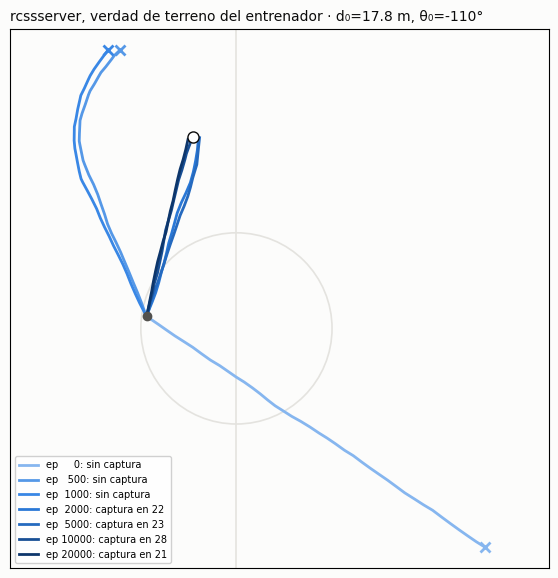

In [4]:
fig, ax = plt.subplots(figsize=(7, 7))
plots.plot_snapshot_trajectories(episodes, 0, "live", ax=ax)
ax.set_title(f"rcssserver, verdad de terreno del entrenador · d₀={start.distance:.1f} m, θ₀={start.bearing:.0f}°",
             fontsize=10, loc="left")
plt.show()

## 3. Animación a velocidad real

Todas las políticas guardadas avanzan a la vez, paso a paso (claro = temprano en el entrenamiento, oscuro = tarde).
El triángulo marca la orientación del cuerpo; ✕, un episodio que terminó sin captura.

In [5]:
plt.rcParams["animation.embed_limit"] = 50
trajs = {k: episodes[k]["live"][0]["trajectory"] for k in keys}
colors = (plots.ORDINAL_BLUES[-len(keys):] if len(keys) <= len(plots.ORDINAL_BLUES)
          else [plots.BLUE_RAMP(x) for x in np.linspace(0.2, 1.0, len(keys))])
n_frames = max(len(t) for t in trajs.values())

fig, ax = plt.subplots(figsize=(6.5, 6.5), dpi=80)
plots.plot_snapshot_trajectories(episodes, 0, "live", ax=ax, legend=False)
for line in list(ax.lines)[:-2]:        # keep only the start and ball markers; the lines are animated
    line.remove()
lines, heads = [], []
for key, color in zip(keys, colors):
    lines.append(ax.plot([], [], color=color, linewidth=2.2,
                         label=f"tras {int(key.split('_')[1])} episodios")[0])
    heads.append(ax.plot([], [], marker=(3, 0, 0), color=color, markersize=11, linestyle="none")[0])
ax.legend(fontsize=8, loc="lower left", framealpha=0.9)
clock = ax.text(0.02, 0.97, "", transform=ax.transAxes, va="top", fontsize=11, color=plots.TEXT)

def frame(t):
    for key, line, head in zip(keys, lines, heads):
        tr = trajs[key][: t + 1]
        line.set_data([s["player"][0] for s in tr], [s["player"][1] for s in tr])
        last = tr[-1]
        # The y-axis is inverted (monitor convention), so a heading φ points to screen angle −φ.
        head.set_data([last["player"][0]], [last["player"][1]])
        head.set_marker((3, 0, -last["body_dir"] - 90))
        done = t >= len(trajs[key]) - 1
        cap = episodes[key]["live"][0]["captured"]
        if done and not cap:
            head.set_marker("x")
    clock.set_text(f"paso {min(t, n_frames - 1):2d} / 40")
    return lines + heads + [clock]

anim = animation.FuncAnimation(fig, frame, frames=n_frames + 10, interval=100, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())

**Qué mostrar en la defensa.** La tabla y la figura salen de episodios que acaban de ejecutarse en el servidor, con
0 comandos perdidos. La política sin entrenar (0 episodios) no captura. Desde unos pocos miles de episodios va casi
en línea recta al balón. Para la política del informe, cambiar `POLICY = "kit"`: en el servidor rinde menos
(≈ 26 %) por la diferencia de física (giros de ≈ 12° en movimiento en lugar de 35°), como se discute en el informe.